# **Tabnet new code**

/tmp/ipykernel_2716/251869442.py:34: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y = df[label_col].replace({
/tmp/ipykernel_2716/251869442.py:34: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y = df[label_col].replace({
/tmp/ipykernel_2716/251869442.py:34: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
 

Round 1/35 completed
Round 2/35 completed
Round 3/35 completed
Round 4/35 completed
Round 5/35 completed
Round 6/35 completed
Round 7/35 completed
Round 8/35 completed
Round 9/35 completed
Round 10/35 completed
Round 11/35 completed
Round 12/35 completed
Round 13/35 completed
Round 14/35 completed
Round 15/35 completed
Round 16/35 completed
Round 17/35 completed
Round 18/35 completed
Round 19/35 completed
Round 20/35 completed
Round 21/35 completed
Round 22/35 completed
Round 23/35 completed
Round 24/35 completed
Round 25/35 completed
Round 26/35 completed
Round 27/35 completed
Round 28/35 completed
Round 29/35 completed
Round 30/35 completed
Round 31/35 completed
Round 32/35 completed
Round 33/35 completed
Round 34/35 completed
Round 35/35 completed

Client-1 FINAL TEST METRICS: {'Accuracy': 0.8367346938775511, 'Precision': 0.8333333333333334, 'Recall': 0.8928571428571429, 'F1': 0.8620689655172413, 'ROC-AUC': np.float64(0.891156462585034), 'Threshold': np.float32(0.3973912)}

Client-2

<Figure size 640x480 with 0 Axes>

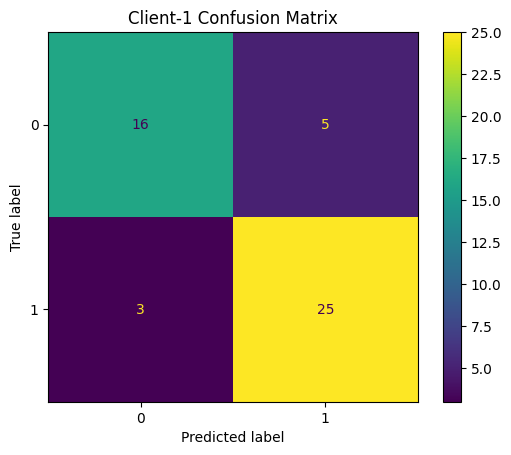

<Figure size 640x480 with 0 Axes>

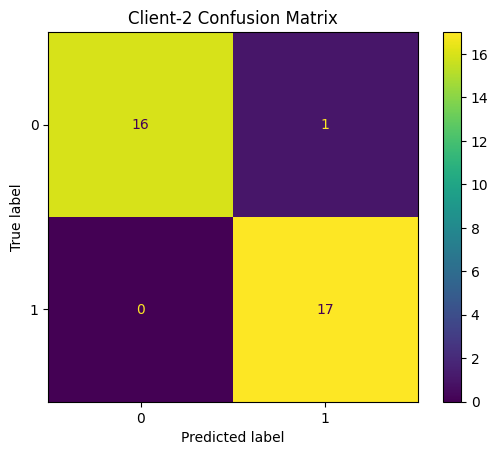

<Figure size 640x480 with 0 Axes>

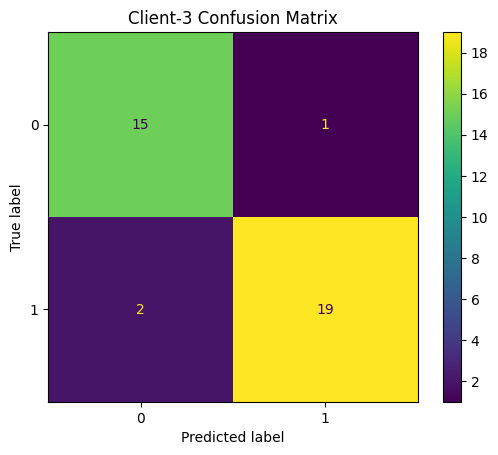

<Figure size 640x480 with 0 Axes>

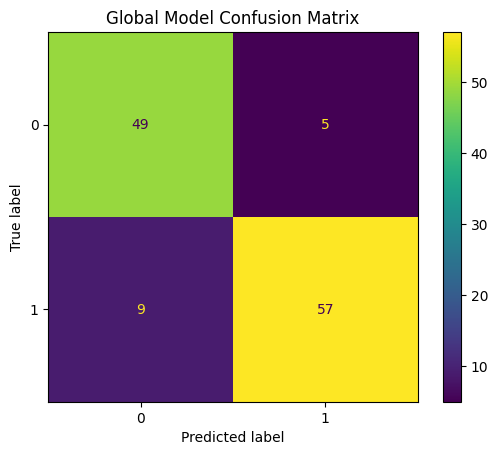

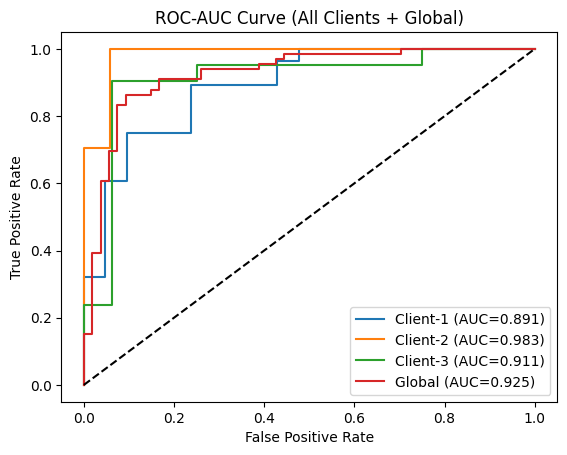

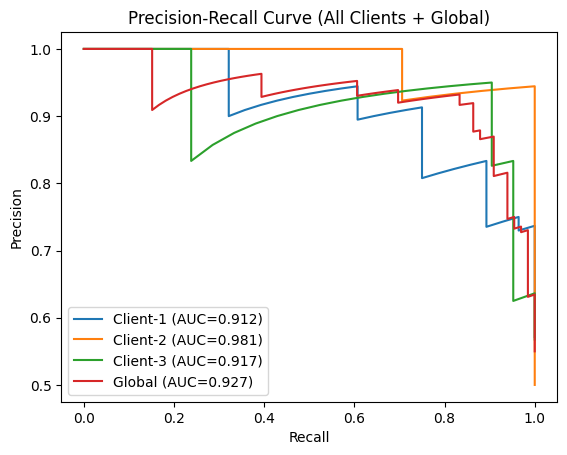

In [ ]:
# ======================================
# 1️⃣ IMPORTS
# ======================================
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

torch.manual_seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"

# ======================================
# 2️⃣ LOAD DATA
# ======================================
paths = [
    "/content/drive/MyDrive/six datasets with common genes/GSE183795_common_genes.csv",
    "/content/drive/MyDrive/Updated Mergred datasets/Merged_GSE28735_GSE15471.csv",
    "/content/drive/MyDrive/Updated Mergred datasets/Merged_GSE62452_GSE16515.csv"
]
dfs = [pd.read_csv(p, low_memory=False) for p in paths]

# ======================================
# 3️⃣ LABEL + FEATURE EXTRACTION
# ======================================
clients_df, clients_y = [], []
for df in dfs:
    label_col = [c for c in df.columns if c.lower()=="label"][0]
    y = df[label_col].replace({
        "Tumor":1,"tumor":1,"TCGA":1,
        "Normal":0,"normal":0,"GTEx":0,"non-tumor":0
    }).astype(np.float32).values

    X = df.drop(columns=[label_col]).select_dtypes(include=[np.number])
    clients_df.append(X)
    clients_y.append(y)

# ======================================
# 4️⃣ COMMON GENES
# ======================================
genes = set(clients_df[0].columns)
for df in clients_df[1:]:
    genes &= set(df.columns)
genes = sorted(list(genes))

clients_df = [df[genes] for df in clients_df]

# ======================================
# 5️⃣ REMOVE NaNs
# ======================================
clean_X, clean_y = [], []
for X,y in zip(clients_df,clients_y):
    mask = np.isnan(X.values).any(axis=1)
    clean_X.append(X.loc[~mask])
    clean_y.append(y[~mask])

clients_df, clients_y = clean_X, clean_y

# ======================================
# 6️⃣ SCALING + FEATURE SELECTION
# ======================================
scaler = StandardScaler()
X_all = scaler.fit_transform(pd.concat(clients_df))

variances = np.var(X_all, axis=0)
TOP_K = min(2000, X_all.shape[1])
idx = np.argsort(variances)[-TOP_K:]

clients_X = [scaler.transform(df)[:, idx].astype(np.float32) for df in clients_df]

# ======================================
# 7️⃣ 80:20 TRAIN TEST SPLIT
# ======================================
clients_train, clients_test = [], []
for X,y in zip(clients_X,clients_y):
    Xtr,Xte,ytr,yte = train_test_split(
        X,y,test_size=0.2,stratify=y,random_state=42
    )
    clients_train.append((Xtr,ytr))
    clients_test.append((Xte,yte))

# ======================================
# 8️⃣ TABNET MODEL (STABLE)
# ======================================
class FeatureBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.fc = nn.Linear(dim, dim)
        self.ln = nn.LayerNorm(dim)
    def forward(self,x):
        return F.leaky_relu(self.ln(self.fc(x)),0.01)

class AttentiveMask(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.fc = nn.Linear(dim, dim)
        self.ln = nn.LayerNorm(dim)
    def forward(self,x):
        return torch.softmax(self.ln(self.fc(x)),dim=1)

class TabNetBackbone(nn.Module):
    def __init__(self,dim,steps=7):
        super().__init__()
        self.steps=steps
        self.shared=FeatureBlock(dim)
        self.attentive=AttentiveMask(dim)
    def forward(self,x):
        prior=torch.ones_like(x)
        out=0
        for _ in range(self.steps):
            xt=self.shared(x*prior)
            mask=self.attentive(xt)
            prior=prior*(1-mask)
            out+=xt
        return out

class TabNet(nn.Module):
    def __init__(self,backbone,dim):
        super().__init__()
        self.backbone=backbone
        self.head=nn.Linear(dim,1)
    def forward(self,x):
        f=self.backbone(x)
        return self.head(f),f

# ======================================
# 9️⃣ LOSSES (FOCAL + CONTRASTIVE + CORAL)
# ======================================
class FocalLoss(nn.Module):
    def __init__(self,alpha=0.75,gamma=2):
        super().__init__()
        self.alpha=alpha
        self.gamma=gamma
    def forward(self,logits,y):
        bce=F.binary_cross_entropy_with_logits(logits,y,reduction='none')
        pt=torch.exp(-bce)
        return (self.alpha*(1-pt)**self.gamma*bce).mean()

def coral_loss(a,b):
    cov_a=torch.cov(a.T)
    cov_b=torch.cov(b.T)
    return ((cov_a-cov_b)**2).mean()

def contrastive_loss(features, labels, temp=0.1):
    f = F.normalize(features, dim=1)
    sim = torch.matmul(f, f.T) / temp
    labels = labels.view(-1,1)
    mask = torch.eq(labels, labels.T).float().to(device)
    exp_sim = torch.exp(sim)
    log_prob = sim - torch.log(exp_sim.sum(dim=1, keepdim=True))
    mean_log_prob_pos = (mask * log_prob).sum(1) / mask.sum(1)
    return -mean_log_prob_pos.mean()

# ======================================
# 🔟 FEDPROX CLIENT TRAINING
# ======================================
def train_client(model,global_weights,X,y,other_feats,epochs=15,mu=0.05):
    model.load_state_dict(global_weights)
    model.train()

    X=torch.tensor(X).to(device)
    y=torch.tensor(y).view(-1,1).to(device)

    opt=torch.optim.Adam(model.parameters(),lr=1e-3)
    focal = FocalLoss()

    global_copy={k:v.clone().detach() for k,v in model.state_dict().items()}

    for _ in range(epochs):
        opt.zero_grad()
        logits,feats=model(X)

        loss = focal(logits,y)
        loss += 0.1 * coral_loss(feats, other_feats)
        loss += 0.05 * contrastive_loss(feats, y)

        prox=0
        for k in model.state_dict():
            prox+=((model.state_dict()[k]-global_copy[k])**2).sum()
        loss += mu * prox

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
        opt.step()

    return model.state_dict(), len(X)

# ======================================
# 11️⃣ FED AGGREGATION
# ======================================
def fed_avg(weights,sizes):
    total=sum(sizes)
    avg={}
    for k in weights[0]:
        avg[k]=sum(weights[i][k]*sizes[i]/total for i in range(len(weights)))
    return avg

# ======================================
# 12️⃣ FEDERATED TRAINING
# ======================================
input_dim = clients_train[0][0].shape[1]
global_backbone = TabNetBackbone(input_dim)
clients_models = [TabNet(global_backbone,input_dim).to(device) for _ in clients_train]

ROUNDS=35
for r in range(ROUNDS):
    ws,ns=[],[]
    mu = 0.05 * (1 - r/ROUNDS)

    for i,m in enumerate(clients_models):
        Xtr,ytr = clients_train[i]
        j = (i+1)%len(clients_models)

        with torch.no_grad():
            _,other_feats = clients_models[j](
                torch.tensor(clients_train[j][0]).to(device)
            )

        w,n = train_client(m,m.state_dict(),Xtr,ytr,other_feats,mu=mu)
        ws.append({k.replace("backbone.",""):v for k,v in w.items() if "backbone." in k})
        ns.append(n)

    avg = fed_avg(ws,ns)
    for m in clients_models:
        m.backbone.load_state_dict(avg)

    print(f"Round {r+1}/{ROUNDS} completed")

# ======================================
# 13️⃣ EVALUATION
# ======================================
def best_threshold(y,probs):
    fpr,tpr,thr = roc_curve(y,probs)
    return thr[np.argmax(tpr-fpr)]

def evaluate(model,X,y):
    model.eval()
    with torch.no_grad():
        logits,_ = model(torch.tensor(X).to(device))
        probs = torch.sigmoid(logits).cpu().numpy().ravel()

    thr = best_threshold(y,probs)
    preds = (probs>=thr).astype(int)

    return {
        "Accuracy": accuracy_score(y,preds),
        "Precision": precision_score(y,preds,zero_division=0),
        "Recall": recall_score(y,preds,zero_division=0),
        "F1": f1_score(y,preds,zero_division=0),
        "ROC-AUC": roc_auc_score(y,probs),
        "Threshold": thr
    }

# ======================================
# 14️⃣ FINAL RESULTS
# ======================================
for i,m in enumerate(clients_models):
    Xte,yte = clients_test[i]
    print(f"\nClient-{i+1} FINAL TEST METRICS:", evaluate(m,Xte,yte))

# GLOBAL METRICS
def evaluate_global(models,clients_test):
    probs_all,y_all=[],[]
    for i,m in enumerate(models):
        Xte,yte = clients_test[i]
        with torch.no_grad():
            logits,_ = m(torch.tensor(Xte).to(device))
            probs = torch.sigmoid(logits).cpu().numpy().ravel()
        probs_all.append(probs)
        y_all.append(yte)

    probs_all = np.concatenate(probs_all)
    y_all = np.concatenate(y_all)

    thr = best_threshold(y_all,probs_all)
    preds = (probs_all>=thr).astype(int)

    return {
        "Accuracy": accuracy_score(y_all,preds),
        "Precision": precision_score(y_all,preds,zero_division=0),
        "Recall": recall_score(y_all,preds,zero_division=0),
        "F1": f1_score(y_all,preds,zero_division=0),
        "ROC-AUC": roc_auc_score(y_all,probs_all),
        "Threshold": thr
    }

print("\n🌍 GLOBAL TEST METRICS:", evaluate_global(clients_models, clients_test))

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_recall_curve, auc

# Store for combined plots
roc_data = []
pr_data = []

# ======================================
# CLIENT-WISE CONFUSION MATRIX + CURVES
# ======================================
for i, m in enumerate(clients_models):
    Xte, yte = clients_test[i]

    m.eval()
    with torch.no_grad():
        logits, _ = m(torch.tensor(Xte).to(device))
        probs = torch.sigmoid(logits).cpu().numpy().ravel()

    # Best threshold
    thr = best_threshold(yte, probs)
    preds = (probs >= thr).astype(int)

    # -------- CONFUSION MATRIX --------
    cm = confusion_matrix(yte, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)

    plt.figure()
    disp.plot()
    plt.title(f"Client-{i+1} Confusion Matrix")
    plt.show()

    # -------- ROC CURVE --------
    fpr, tpr, _ = roc_curve(yte, probs)
    roc_auc = roc_auc_score(yte, probs)
    roc_data.append((fpr, tpr, roc_auc, f"Client-{i+1}"))

    # -------- PR CURVE --------
    precision, recall, _ = precision_recall_curve(yte, probs)
    pr_auc = auc(recall, precision)
    pr_data.append((recall, precision, pr_auc, f"Client-{i+1}"))


# ======================================
# GLOBAL MODEL CURVES + CONFUSION MATRIX
# ======================================
probs_all, y_all = [], []

for i, m in enumerate(clients_models):
    Xte, yte = clients_test[i]
    with torch.no_grad():
        logits, _ = m(torch.tensor(Xte).to(device))
        probs = torch.sigmoid(logits).cpu().numpy().ravel()

    probs_all.append(probs)
    y_all.append(yte)

probs_all = np.concatenate(probs_all)
y_all = np.concatenate(y_all)

# Threshold
thr_global = best_threshold(y_all, probs_all)
preds_global = (probs_all >= thr_global).astype(int)

# -------- GLOBAL CONFUSION MATRIX --------
cm = confusion_matrix(y_all, preds_global)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

plt.figure()
disp.plot()
plt.title("Global Model Confusion Matrix")
plt.show()

# -------- GLOBAL ROC --------
fpr, tpr, _ = roc_curve(y_all, probs_all)
roc_auc = roc_auc_score(y_all, probs_all)
roc_data.append((fpr, tpr, roc_auc, "Global"))

# -------- GLOBAL PR --------
precision, recall, _ = precision_recall_curve(y_all, probs_all)
pr_auc = auc(recall, precision)
pr_data.append((recall, precision, pr_auc, "Global"))


# ======================================
# COMBINED ROC CURVE (ALL MODELS)
# ======================================
plt.figure()

for fpr, tpr, roc_auc, label in roc_data:
    plt.plot(fpr, tpr, label=f"{label} (AUC={roc_auc:.3f})")

plt.plot([0,1],[0,1],'k--')  # random classifier
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curve (All Clients + Global)")
plt.legend()
plt.show()


# ======================================
# COMBINED PRECISION-RECALL CURVE
# ======================================
plt.figure()

for recall, precision, pr_auc, label in pr_data:
    plt.plot(recall, precision, label=f"{label} (AUC={pr_auc:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (All Clients + Global)")
plt.legend()
plt.show()

# **XGBoost new code**

/tmp/ipykernel_3296/4058678211.py:34: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y = df[label_col].replace({
/tmp/ipykernel_3296/4058678211.py:34: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y = df[label_col].replace({
/tmp/ipykernel_3296/4058678211.py:34: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)

Round 1/35 - Avg LogLoss: 0.0414
Round 2/35 - Avg LogLoss: 0.0414
Round 3/35 - Avg LogLoss: 0.0414
Round 4/35 - Avg LogLoss: 0.0414
Round 5/35 - Avg LogLoss: 0.0414
Round 6/35 - Avg LogLoss: 0.0414
Round 7/35 - Avg LogLoss: 0.0414
Round 8/35 - Avg LogLoss: 0.0414
Round 9/35 - Avg LogLoss: 0.0414
Round 10/35 - Avg LogLoss: 0.0414
Round 11/35 - Avg LogLoss: 0.0414
Round 12/35 - Avg LogLoss: 0.0414
Round 13/35 - Avg LogLoss: 0.0414
Round 14/35 - Avg LogLoss: 0.0414
Round 15/35 - Avg LogLoss: 0.0414
Round 16/35 - Avg LogLoss: 0.0414
Round 17/35 - Avg LogLoss: 0.0414
Round 18/35 - Avg LogLoss: 0.0414
Round 19/35 - Avg LogLoss: 0.0414
Round 20/35 - Avg LogLoss: 0.0414
Round 21/35 - Avg LogLoss: 0.0414
Round 22/35 - Avg LogLoss: 0.0414
Round 23/35 - Avg LogLoss: 0.0414
Round 24/35 - Avg LogLoss: 0.0414
Round 25/35 - Avg LogLoss: 0.0414
Round 26/35 - Avg LogLoss: 0.0414
Round 27/35 - Avg LogLoss: 0.0414
Round 28/35 - Avg LogLoss: 0.0414
Round 29/35 - Avg LogLoss: 0.0414
Round 30/35 - Avg LogLo

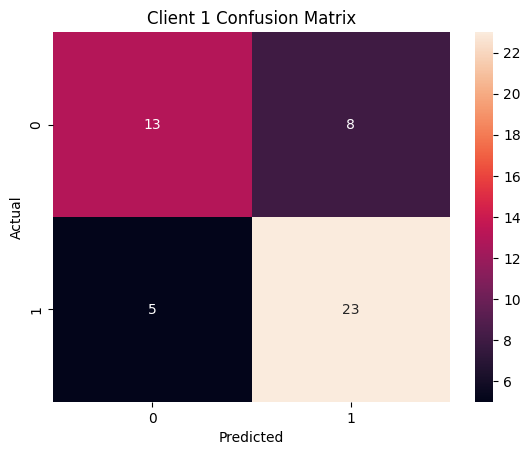


Client 2 Metrics:
Accuracy: 0.8529
Precision: 0.8000
Recall: 0.9412
F1: 0.8649
ROC-AUC: 0.9066


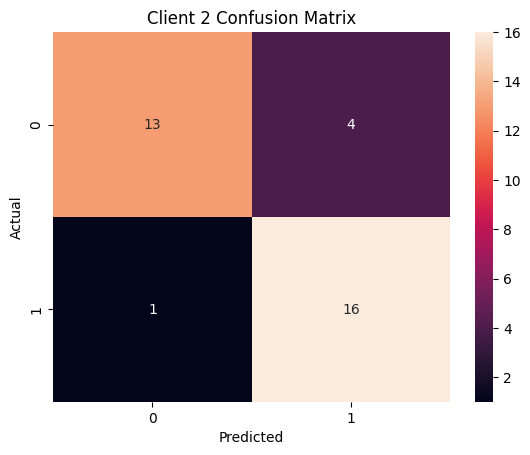


Client 3 Metrics:
Accuracy: 0.8108
Precision: 0.7917
Recall: 0.9048
F1: 0.8444
ROC-AUC: 0.8929


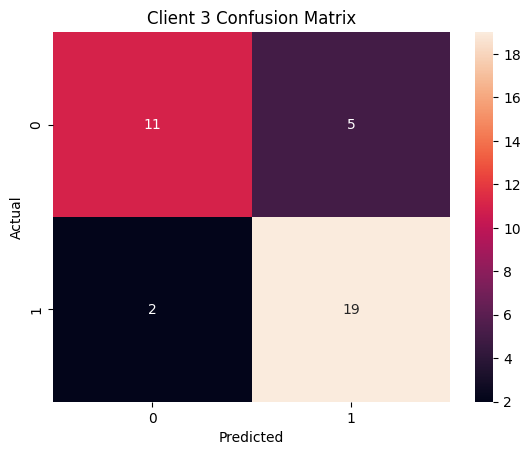


================ GLOBAL METRICS ================
Accuracy: 0.7917
Precision: 0.7733
Recall: 0.8788
F1: 0.8227
ROC-AUC: 0.8751


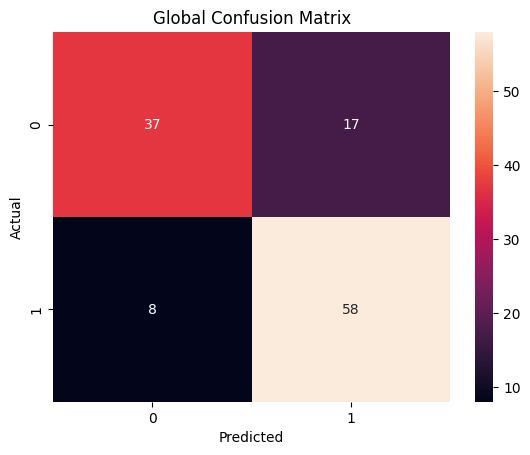

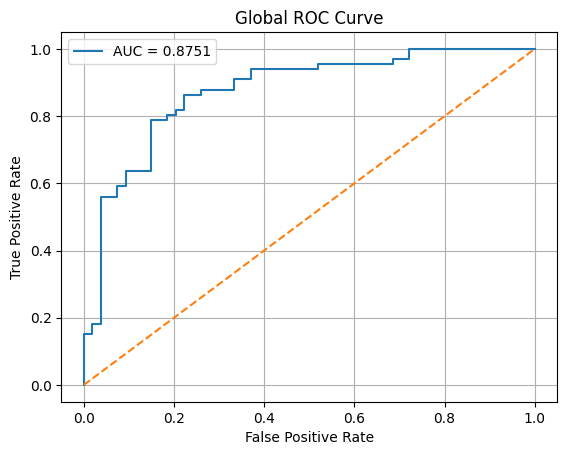

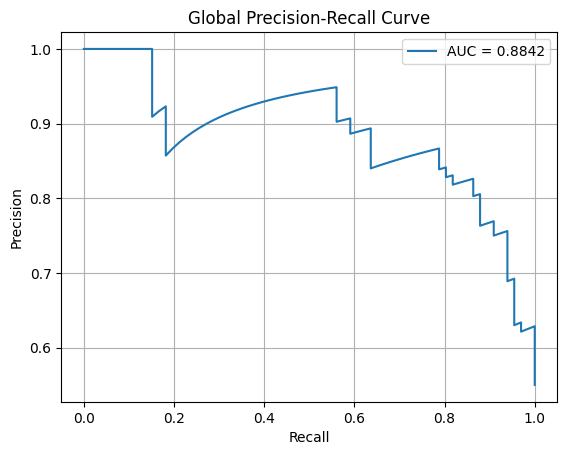

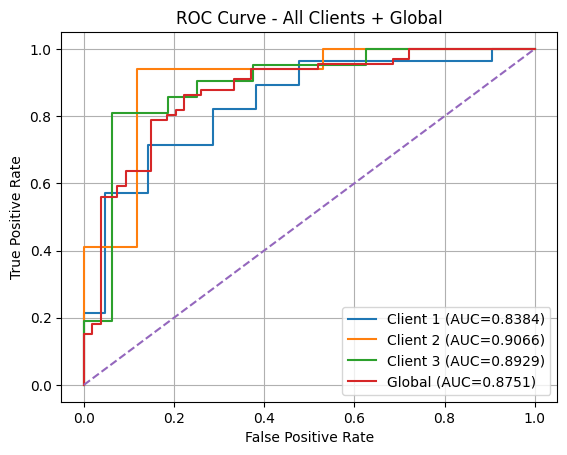

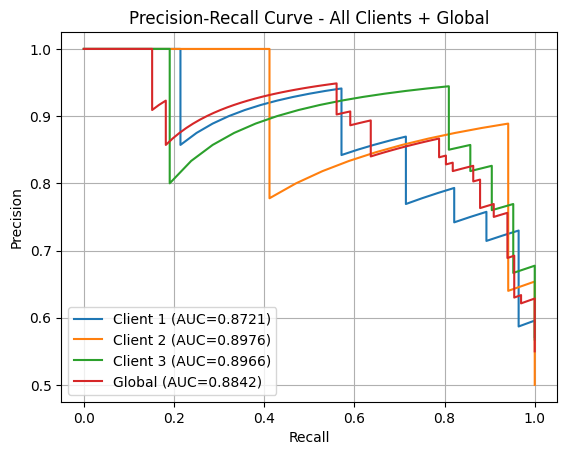

In [ ]:
# ======================================
# 0️⃣ IMPORTS
# ======================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix,
    roc_curve, precision_recall_curve, auc
)

import xgboost as xgb

# ======================================
# 1️⃣ LOAD & PREPROCESS DATA
# ======================================
paths = [
    "/content/drive/MyDrive/six datasets with common genes/GSE183795_common_genes.csv",
    "/content/drive/MyDrive/Updated Mergred datasets/Merged_GSE28735_GSE15471.csv",
    "/content/drive/MyDrive/Updated Mergred datasets/Merged_GSE62452_GSE16515.csv"
]

dfs = [pd.read_csv(p, low_memory=False) for p in paths]

clients_df, clients_y = [], []

for df in dfs:
    label_col = [c for c in df.columns if c.lower()=="label"][0]
    y = df[label_col].replace({
        "Tumor":1,"tumor":1,"TCGA":1,
        "Normal":0,"normal":0,"GTEx":0,"non-tumor":0
    }).astype(np.float32).values

    X = df.drop(columns=[label_col]).select_dtypes(include=[np.number])
    clients_df.append(X)
    clients_y.append(y)

# COMMON GENES
genes = set(clients_df[0].columns)
for df in clients_df[1:]:
    genes &= set(df.columns)

genes = sorted(list(genes))
clients_df = [df[genes] for df in clients_df]

# REMOVE NaNs
clean_X, clean_y = [], []
for X,y in zip(clients_df,clients_y):
    mask = np.isnan(X.values).any(axis=1)
    clean_X.append(X.loc[~mask])
    clean_y.append(y[~mask])

clients_df, clients_y = clean_X, clean_y

# SCALING + VARIANCE FILTER
scaler = StandardScaler()
X_all = scaler.fit_transform(pd.concat(clients_df))
variances = np.var(X_all, axis=0)

TOP_K = min(2000, X_all.shape[1])
idx = np.argsort(variances)[-TOP_K:]

clients_X = [scaler.transform(df)[:, idx].astype(np.float32) for df in clients_df]

# TRAIN-TEST SPLIT
clients_train, clients_test = [], []

for X,y in zip(clients_X,clients_y):
    Xtr,Xte,ytr,yte = train_test_split(
        X,y,test_size=0.2,stratify=y,random_state=42
    )
    clients_train.append((Xtr,ytr))
    clients_test.append((Xte,yte))

# ======================================
# 2️⃣ FEDERATED TRAINING (XGBoost)
# ======================================
ROUNDS = 35
FL_loss_curve = []
global_models = [None]*len(clients_train)

for r in range(ROUNDS):
    round_losses = []

    for i,(Xtr,ytr) in enumerate(clients_train):
        dtrain = xgb.DMatrix(Xtr,label=ytr)

        params = {
            "objective":"binary:logistic",
            "eval_metric":"logloss",
            "eta":0.1,
            "max_depth":6,
            "seed":42
        }

        bst = xgb.train(params,dtrain,num_boost_round=50,verbose_eval=False)
        global_models[i] = bst

        preds = bst.predict(dtrain)
        loss = -np.mean(ytr*np.log(preds+1e-8) + (1-ytr)*np.log(1-preds+1e-8))
        round_losses.append(loss)

    FL_loss_curve.append(np.mean(round_losses))
    print(f"Round {r+1}/{ROUNDS} - Avg LogLoss: {np.mean(round_losses):.4f}")

# ======================================
# 3️⃣ EVALUATION FUNCTIONS
# ======================================
def compute_metrics(y_true, probs, threshold=0.5):
    preds = (probs >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true,preds),
        "Precision": precision_score(y_true,preds),
        "Recall": recall_score(y_true,preds),
        "F1": f1_score(y_true,preds),
        "ROC-AUC": roc_auc_score(y_true,probs)
    }

# ======================================
# 4️⃣ CLIENT-WISE EVALUATION
# ======================================
print("\n================ CLIENT METRICS ================")

global_probs, global_labels = [], []

for i,(Xte,yte) in enumerate(clients_test):
    dtest = xgb.DMatrix(Xte)
    probs = global_models[i].predict(dtest)

    metrics = compute_metrics(yte, probs)
    print(f"\nClient {i+1} Metrics:")
    for k,v in metrics.items():
        print(f"{k}: {v:.4f}")

    # Confusion Matrix
    preds = (probs >= 0.5).astype(int)
    cm = confusion_matrix(yte,preds)

    plt.figure()
    sns.heatmap(cm, annot=True, fmt="d")
    plt.title(f"Client {i+1} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    global_probs.append(probs)
    global_labels.append(yte)

# ======================================
# 5️⃣ GLOBAL EVALUATION
# ======================================
print("\n================ GLOBAL METRICS ================")

global_probs = np.concatenate(global_probs)
global_labels = np.concatenate(global_labels)

global_metrics = compute_metrics(global_labels, global_probs)

for k,v in global_metrics.items():
    print(f"{k}: {v:.4f}")

# Global Confusion Matrix
global_preds = (global_probs >= 0.5).astype(int)
cm = confusion_matrix(global_labels, global_preds)

plt.figure()
sns.heatmap(cm, annot=True, fmt="d")
plt.title("Global Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ======================================
# 6️⃣ ROC CURVE
# ======================================
fpr, tpr, _ = roc_curve(global_labels, global_probs)
roc_auc = auc(fpr,tpr)

plt.figure()
plt.plot(fpr,tpr,label=f"AUC = {roc_auc:.4f}")
plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Global ROC Curve")
plt.legend()
plt.grid()
plt.show()

# ======================================
# 7️⃣ PRECISION-RECALL CURVE
# ======================================
precision, recall, _ = precision_recall_curve(global_labels, global_probs)
pr_auc = auc(recall, precision)

plt.figure()
plt.plot(recall,precision,label=f"AUC = {pr_auc:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Global Precision-Recall Curve")
plt.legend()
plt.grid()
plt.show()

# ======================================
# 9️⃣ COMBINED ROC + PR CURVES (ALL CLIENTS + GLOBAL)
# ======================================

roc_curves = []
pr_curves = []

# -------- CLIENT CURVES --------
for i, (Xte, yte) in enumerate(clients_test):
    dtest = xgb.DMatrix(Xte)
    probs = global_models[i].predict(dtest)

    # ROC
    fpr, tpr, _ = roc_curve(yte, probs)
    roc_auc = auc(fpr, tpr)
    roc_curves.append((fpr, tpr, roc_auc, f"Client {i+1}"))

    # PR
    precision, recall, _ = precision_recall_curve(yte, probs)
    pr_auc = auc(recall, precision)
    pr_curves.append((recall, precision, pr_auc, f"Client {i+1}"))

# -------- GLOBAL CURVES --------
fpr, tpr, _ = roc_curve(global_labels, global_probs)
roc_auc = auc(fpr, tpr)
roc_curves.append((fpr, tpr, roc_auc, "Global"))

precision, recall, _ = precision_recall_curve(global_labels, global_probs)
pr_auc = auc(recall, precision)
pr_curves.append((recall, precision, pr_auc, "Global"))

# ======================================
# 🔟 PLOT COMBINED ROC CURVE
# ======================================
plt.figure()

for fpr, tpr, roc_auc, label in roc_curves:
    plt.plot(fpr, tpr, label=f"{label} (AUC={roc_auc:.4f})")

plt.plot([0,1],[0,1],'--')  # random baseline
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - All Clients + Global")
plt.legend()
plt.grid()
plt.show()

# ======================================
# 1️⃣1️⃣ PLOT COMBINED PR CURVE
# ======================================
plt.figure()

for recall, precision, pr_auc, label in pr_curves:
    plt.plot(recall, precision, label=f"{label} (AUC={pr_auc:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - All Clients + Global")
plt.legend()
plt.grid()
plt.show()



# **Random Forest New Code**

/tmp/ipykernel_612/405181467.py:29: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y = df[label_col].replace({
/tmp/ipykernel_612/405181467.py:29: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y = df[label_col].replace({
/tmp/ipykernel_612/405181467.py:29: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y 

Round 1/35 - Avg client logloss: 0.1165
Round 2/35 - Avg client logloss: 0.1165
Round 3/35 - Avg client logloss: 0.1165
Round 4/35 - Avg client logloss: 0.1165
Round 5/35 - Avg client logloss: 0.1165
Round 6/35 - Avg client logloss: 0.1165
Round 7/35 - Avg client logloss: 0.1165
Round 8/35 - Avg client logloss: 0.1165
Round 9/35 - Avg client logloss: 0.1165
Round 10/35 - Avg client logloss: 0.1165
Round 11/35 - Avg client logloss: 0.1165
Round 12/35 - Avg client logloss: 0.1165
Round 13/35 - Avg client logloss: 0.1165
Round 14/35 - Avg client logloss: 0.1165
Round 15/35 - Avg client logloss: 0.1165
Round 16/35 - Avg client logloss: 0.1165
Round 17/35 - Avg client logloss: 0.1165
Round 18/35 - Avg client logloss: 0.1165
Round 19/35 - Avg client logloss: 0.1165
Round 20/35 - Avg client logloss: 0.1165
Round 21/35 - Avg client logloss: 0.1165
Round 22/35 - Avg client logloss: 0.1165
Round 23/35 - Avg client logloss: 0.1165
Round 24/35 - Avg client logloss: 0.1165
Round 25/35 - Avg client 

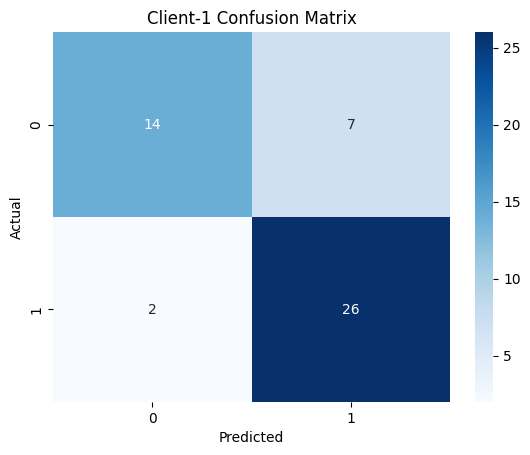


Client-2 Confusion Matrix:
[[13  4]
 [ 1 16]]


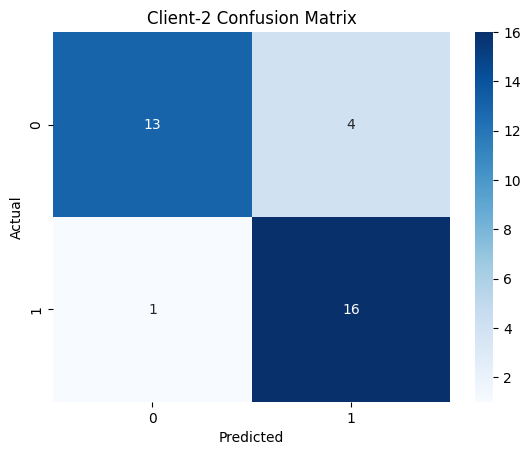


Client-3 Confusion Matrix:
[[11  5]
 [ 2 19]]


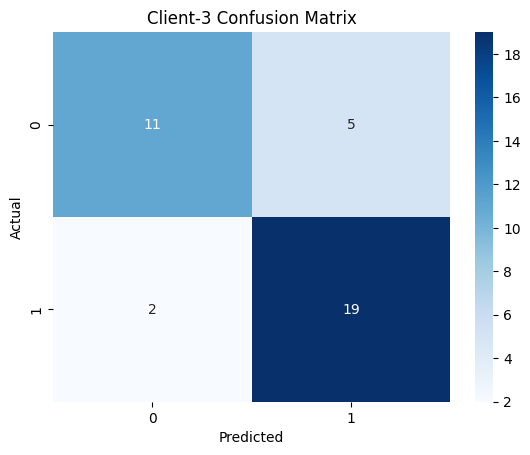


Global Confusion Matrix:
 [[38 16]
 [ 5 61]]


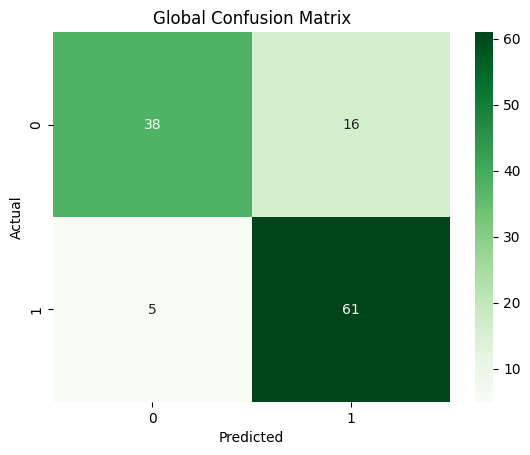

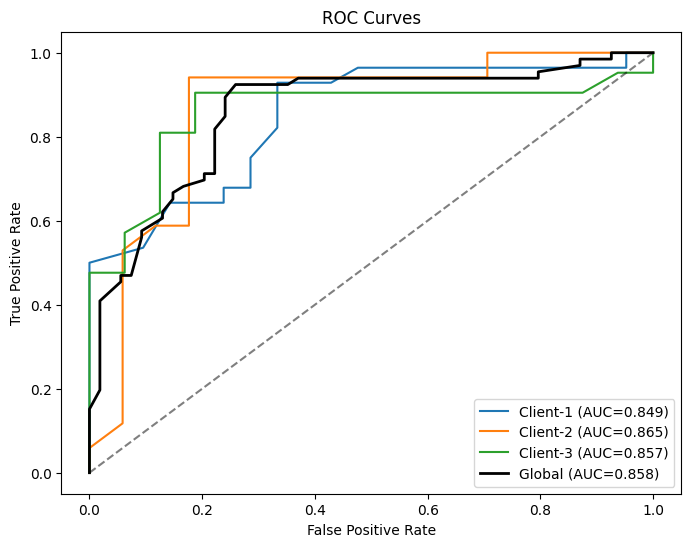

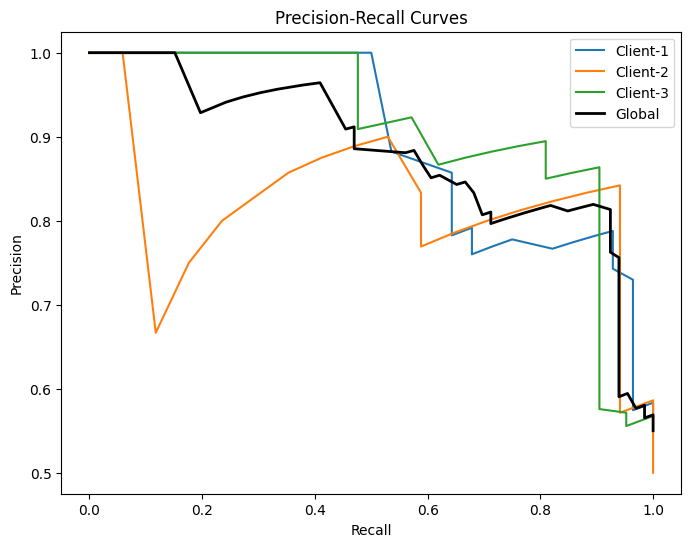

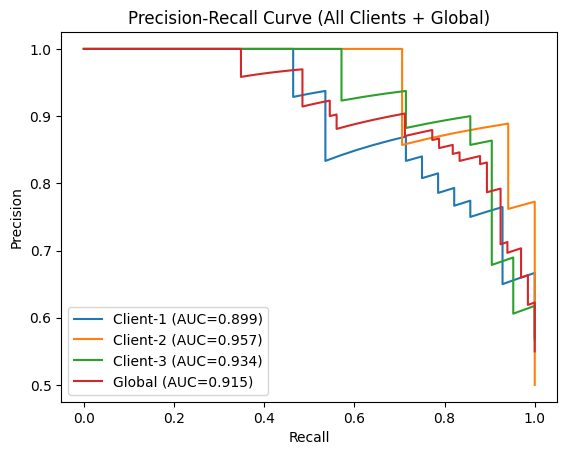

In [ ]:
# ======================================
# 0️⃣ IMPORTS
# ======================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, precision_recall_curve, log_loss
)
from sklearn.ensemble import RandomForestClassifier
import seaborn as sns

# ======================================
# 1️⃣ LOAD & PREPROCESS DATA
# ======================================
paths = [
    "/content/drive/MyDrive/six datasets with common genes/GSE183795_common_genes.csv",
    "/content/drive/MyDrive/Updated Mergred datasets/Merged_GSE28735_GSE15471.csv",
    "/content/drive/MyDrive/Updated Mergred datasets/Merged_GSE62452_GSE16515.csv"
]
dfs = [pd.read_csv(p, low_memory=False) for p in paths]

clients_df, clients_y = [], []
for df in dfs:
    label_col = [c for c in df.columns if c.lower() == "label"][0]
    y = df[label_col].replace({
        "Tumor":1,"tumor":1,"TCGA":1,
        "Normal":0,"normal":0,"GTEx":0,"non-tumor":0
    }).astype(np.float32).values
    X = df.drop(columns=[label_col]).select_dtypes(include=[np.number])
    clients_df.append(X)
    clients_y.append(y)

# COMMON GENES
genes = set(clients_df[0].columns)
for df in clients_df[1:]:
    genes &= set(df.columns)
genes = sorted(list(genes))
clients_df = [df[genes] for df in clients_df]

# REMOVE NaNs
clean_X, clean_y = [], []
for X,y in zip(clients_df,clients_y):
    mask = np.isnan(X.values).any(axis=1)
    clean_X.append(X.loc[~mask])
    clean_y.append(y[~mask])
clients_df, clients_y = clean_X, clean_y

# SCALING + VARIANCE FILTER
scaler = StandardScaler()
X_all = scaler.fit_transform(pd.concat(clients_df))
variances = np.var(X_all, axis=0)
TOP_K = min(2000, X_all.shape[1])
idx = np.argsort(variances)[-TOP_K:]
clients_X = [scaler.transform(df)[:, idx].astype(np.float32) for df in clients_df]

# TRAIN-TEST SPLIT
clients_train, clients_test = [], []
for X,y in zip(clients_X, clients_y):
    Xtr, Xte, ytr, yte = train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)
    clients_train.append((Xtr,ytr))
    clients_test.append((Xte,yte))

# ======================================
# 2️⃣ FEDERATED TRAINING RANDOM FOREST
# ======================================
ROUNDS = 35
FL_loss_curve = []
global_models = [None]*len(clients_train)

for r in range(ROUNDS):
    round_losses = []
    for i,(Xtr,ytr) in enumerate(clients_train):
        # Train Random Forest for this client
        clf = RandomForestClassifier(
            n_estimators=100, max_depth=None, random_state=42
        )
        clf.fit(Xtr,ytr)
        global_models[i] = clf

        # Compute logloss
        probs = clf.predict_proba(Xtr)[:,1]
        loss = log_loss(ytr, probs) # Removed 'eps' argument
        round_losses.append(loss)
    FL_loss_curve.append(np.mean(round_losses))
    print(f"Round {r+1}/{ROUNDS} - Avg client logloss: {np.mean(round_losses):.4f}")

# ======================================
# 3️⃣ METRIC FUNCTIONS
# ======================================
def evaluate_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true,y_pred),
        "Precision": precision_score(y_true,y_pred,zero_division=0),
        "Recall": recall_score(y_true,y_pred,zero_division=0),
        "F1": f1_score(y_true,y_pred,zero_division=0),
        "ROC-AUC": roc_auc_score(y_true,y_prob),
        "Threshold": threshold,
        "y_pred": y_pred,
        "y_prob": y_prob
    }

# ======================================
# 4️⃣ CLIENT & GLOBAL METRICS
# ======================================
all_y_true, all_y_pred, all_y_prob = [], [], []
client_metrics = []

for i,(Xte,yte) in enumerate(clients_test):
    probs = global_models[i].predict_proba(Xte)[:,1]
    metrics = evaluate_metrics(yte, probs, threshold=0.5)
    client_metrics.append(metrics)
    all_y_true.append(yte)
    all_y_pred.append(metrics["y_pred"])
    all_y_prob.append(metrics["y_prob"])
    print(f"\nClient-{i+1} METRICS:")
    for k,v in metrics.items():
        if k not in ["y_pred","y_prob"]:
            print(f"{k}: {v:.4f}")

# GLOBAL METRICS
y_global_true = np.concatenate(all_y_true)
y_global_pred = np.concatenate(all_y_pred)
y_global_prob = np.concatenate(all_y_prob)
global_metrics = evaluate_metrics(y_global_true, y_global_prob)
print("\n🌍 GLOBAL METRICS:")
for k,v in global_metrics.items():
    if k not in ["y_pred","y_prob"]:
        print(f"{k}: {v:.4f}")

# ======================================
# 5️⃣ CONFUSION MATRICES
# ======================================
for i, metrics in enumerate(client_metrics):
    cm = confusion_matrix(clients_test[i][1], metrics["y_pred"])
    print(f"\nClient-{i+1} Confusion Matrix:\n{cm}")
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Client-{i+1} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

cm = confusion_matrix(y_global_true, y_global_pred)
print("\nGlobal Confusion Matrix:\n", cm)
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens")
plt.title("Global Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ======================================
# 6️⃣ ROC CURVES
# ======================================
plt.figure(figsize=(8,6))
for i, metrics in enumerate(client_metrics):
    fpr,tpr,_ = roc_curve(clients_test[i][1], metrics["y_prob"])
    plt.plot(fpr,tpr,label=f"Client-{i+1} (AUC={metrics['ROC-AUC']:.3f})")
fpr,tpr,_ = roc_curve(y_global_true, y_global_prob)
plt.plot(fpr,tpr,label=f"Global (AUC={global_metrics['ROC-AUC']:.3f})", color="black", linewidth=2)
plt.plot([0,1],[0,1],'k--', alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

# ======================================
# 7️⃣ PRECISION-RECALL CURVES
# ======================================
plt.figure(figsize=(8,6))
for i, metrics in enumerate(client_metrics):
    prec, rec, _ = precision_recall_curve(clients_test[i][1], metrics["y_prob"])
    plt.plot(rec, prec, label=f"Client-{i+1}")
prec, rec, _ = precision_recall_curve(y_global_true, y_global_prob)
plt.plot(rec, prec, label="Global", color="black", linewidth=2)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.show()

# ======================================
# 8️⃣ FL LOSS CURVE
# ======================================
plt.figure()

for recall, precision, pr_auc, label in pr_data:
    plt.plot(recall, precision, label=f"{label} (AUC={pr_auc:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (All Clients + Global)")
plt.legend()
plt.show()

# **LIGHTGBM New Code**

/tmp/ipykernel_612/1701109413.py:29: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y = df[label_col].replace({
/tmp/ipykernel_612/1701109413.py:29: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y = df[label_col].replace({
/tmp/ipykernel_612/1701109413.py:29: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
 

Round 1/35 - Avg client logloss: 0.0340
Round 2/35 - Avg client logloss: 0.0340
Round 3/35 - Avg client logloss: 0.0340
Round 4/35 - Avg client logloss: 0.0340
Round 5/35 - Avg client logloss: 0.0340
Round 6/35 - Avg client logloss: 0.0340
Round 7/35 - Avg client logloss: 0.0340
Round 8/35 - Avg client logloss: 0.0340
Round 9/35 - Avg client logloss: 0.0340
Round 10/35 - Avg client logloss: 0.0340
Round 11/35 - Avg client logloss: 0.0340
Round 12/35 - Avg client logloss: 0.0340
Round 13/35 - Avg client logloss: 0.0340
Round 14/35 - Avg client logloss: 0.0340
Round 15/35 - Avg client logloss: 0.0340
Round 16/35 - Avg client logloss: 0.0340
Round 17/35 - Avg client logloss: 0.0340
Round 18/35 - Avg client logloss: 0.0340
Round 19/35 - Avg client logloss: 0.0340
Round 20/35 - Avg client logloss: 0.0340
Round 21/35 - Avg client logloss: 0.0340
Round 22/35 - Avg client logloss: 0.0340
Round 23/35 - Avg client logloss: 0.0340
Round 24/35 - Avg client logloss: 0.0340
Round 25/35 - Avg client 

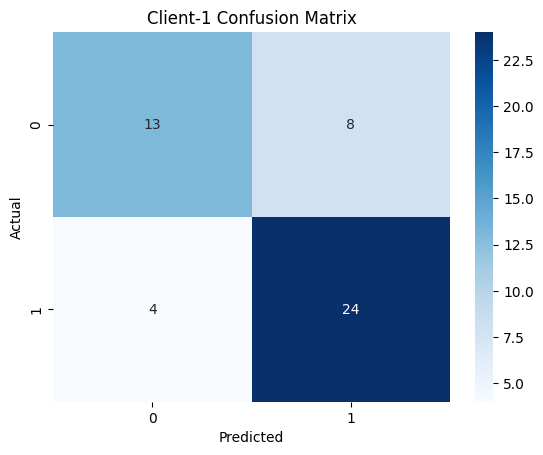


Client-2 Confusion Matrix:
[[15  2]
 [ 1 16]]


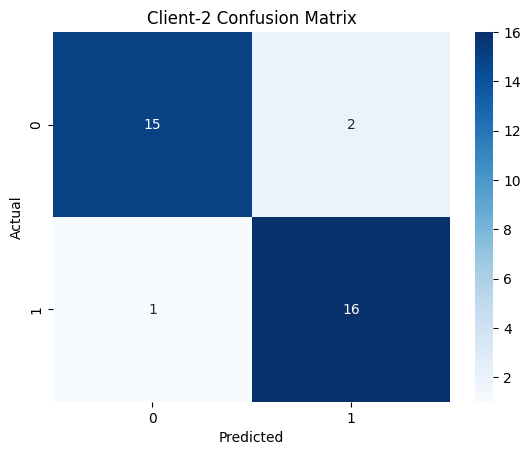


Client-3 Confusion Matrix:
[[11  5]
 [ 2 19]]


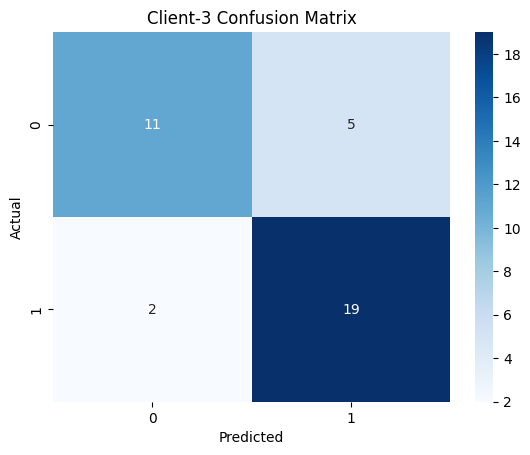


Global Confusion Matrix:
 [[39 15]
 [ 7 59]]


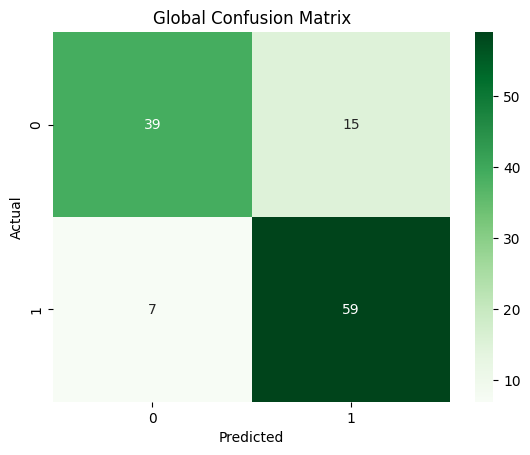

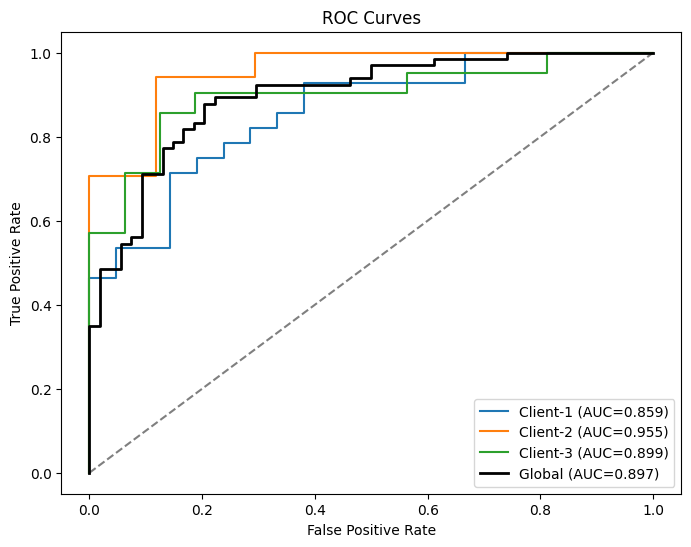

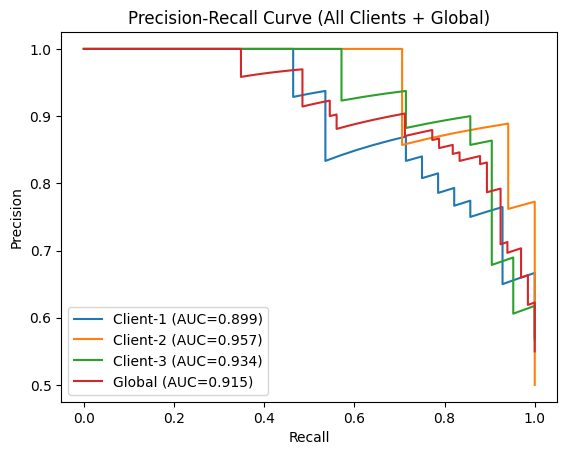

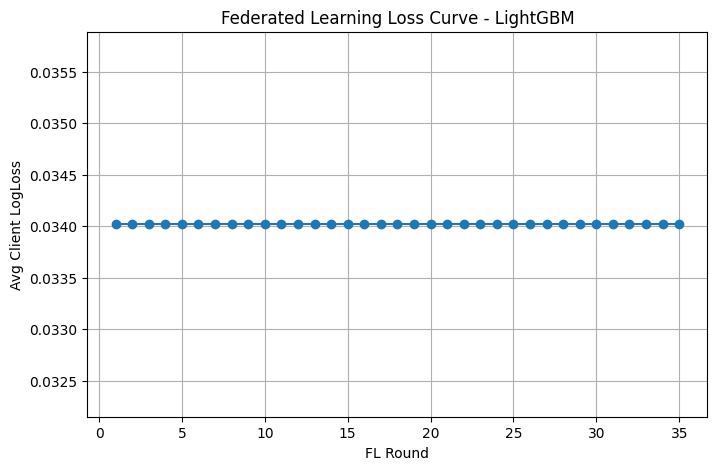

In [ ]:
# ======================================
# 0️⃣ IMPORTS
# ======================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, precision_recall_curve, auc
)
import lightgbm as lgb
import seaborn as sns

# ======================================
# 1️⃣ LOAD & PREPROCESS DATA
# ======================================
paths = [
    "/content/drive/MyDrive/six datasets with common genes/GSE183795_common_genes.csv",
    "/content/drive/MyDrive/Updated Mergred datasets/Merged_GSE28735_GSE15471.csv",
    "/content/drive/MyDrive/Updated Mergred datasets/Merged_GSE62452_GSE16515.csv"
]
dfs = [pd.read_csv(p, low_memory=False) for p in paths]

clients_df, clients_y = [], []
for df in dfs:
    label_col = [c for c in df.columns if c.lower() == "label"][0]
    y = df[label_col].replace({
        "Tumor":1,"tumor":1,"TCGA":1,
        "Normal":0,"normal":0,"GTEx":0,"non-tumor":0
    }).infer_objects(copy=False).astype(np.float32).values
    X = df.drop(columns=[label_col]).select_dtypes(include=[np.number])
    clients_df.append(X)
    clients_y.append(y)

# COMMON GENES
genes = set(clients_df[0].columns)
for df in clients_df[1:]:
    genes &= set(df.columns)
genes = sorted(list(genes))
clients_df = [df[genes] for df in clients_df]

# REMOVE NaNs
clean_X, clean_y = [], []
for X,y in zip(clients_df,clients_y):
    mask = np.isnan(X.values).any(axis=1)
    clean_X.append(X.loc[~mask])
    clean_y.append(y[~mask])
clients_df, clients_y = clean_X, clean_y

# SCALING + VARIANCE FILTER
scaler = StandardScaler()
X_all = scaler.fit_transform(pd.concat(clients_df))
variances = np.var(X_all, axis=0)
TOP_K = min(2000, X_all.shape[1])
idx = np.argsort(variances)[-TOP_K:]
clients_X = [scaler.transform(df)[:, idx].astype(np.float32) for df in clients_df]

# TRAIN-TEST SPLIT
clients_train, clients_test = [], []
for X,y in zip(clients_X, clients_y):
    Xtr, Xte, ytr, yte = train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)
    clients_train.append((Xtr,ytr))
    clients_test.append((Xte,yte))

# ======================================
# 2️⃣ FEDERATED TRAINING LIGHTGBM
# ======================================
ROUNDS = 35
FL_loss_curve = []
global_models = [None]*len(clients_train)

for r in range(ROUNDS):
    round_losses = []
    for i,(Xtr,ytr) in enumerate(clients_train):
        dtrain = lgb.Dataset(Xtr,label=ytr)
        params = {
            "objective":"binary",
            "metric":"binary_logloss",
            "learning_rate":0.05,
            "num_leaves":31,
            "verbose":-1,
            "seed":42
        }
        bst = lgb.train(params,dtrain,num_boost_round=100)
        global_models[i] = bst

        # Compute logloss
        preds = bst.predict(Xtr)
        loss = -np.mean(ytr*np.log(preds+1e-8) + (1-ytr)*np.log(1-preds+1e-8))
        round_losses.append(loss)
    FL_loss_curve.append(np.mean(round_losses))
    print(f"Round {r+1}/{ROUNDS} - Avg client logloss: {np.mean(round_losses):.4f}")

# ======================================
# 3️⃣ EVALUATION FUNCTIONS
# ======================================
def evaluate_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true,y_pred),
        "Precision": precision_score(y_true,y_pred,zero_division=0),
        "Recall": recall_score(y_true,y_pred,zero_division=0),
        "F1": f1_score(y_true,y_pred,zero_division=0),
        "ROC-AUC": roc_auc_score(y_true,y_prob),
        "Threshold": threshold,
        "y_pred": y_pred,
        "y_prob": y_prob
    }

# ======================================
# 4️⃣ CLIENT & GLOBAL METRICS
# ======================================
all_y_true, all_y_pred, all_y_prob = [], [], []
client_metrics = []

for i,(Xte,yte) in enumerate(clients_test):
    probs = global_models[i].predict(Xte)
    thr = 0.5
    metrics = evaluate_metrics(yte,probs,threshold=thr)
    client_metrics.append(metrics)
    all_y_true.append(yte)
    all_y_pred.append(metrics["y_pred"])
    all_y_prob.append(metrics["y_prob"])
    print(f"\nClient-{i+1} METRICS:")
    for k,v in metrics.items():
        if k not in ["y_pred","y_prob"]:
            print(f"{k}: {v:.4f}")

# GLOBAL METRICS
y_global_true = np.concatenate(all_y_true)
y_global_pred = np.concatenate(all_y_pred)
y_global_prob = np.concatenate(all_y_prob)
global_metrics = evaluate_metrics(y_global_true, y_global_prob)
print("\n🌍 GLOBAL METRICS:")
for k,v in global_metrics.items():
    if k not in ["y_pred","y_prob"]:
        print(f"{k}: {v:.4f}")

# ======================================
# 5️⃣ CONFUSION MATRICES
# ======================================
for i, metrics in enumerate(client_metrics):
    cm = confusion_matrix(clients_test[i][1], metrics["y_pred"])
    print(f"\nClient-{i+1} Confusion Matrix:\n{cm}")
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Client-{i+1} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

cm = confusion_matrix(y_global_true, y_global_pred)
print("\nGlobal Confusion Matrix:\n", cm)
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens")
plt.title("Global Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ======================================
# 6️⃣ ROC CURVES
# ======================================
plt.figure(figsize=(8,6))
for i, metrics in enumerate(client_metrics):
    fpr,tpr,_ = roc_curve(clients_test[i][1], metrics["y_prob"])
    plt.plot(fpr,tpr,label=f"Client-{i+1} (AUC={metrics['ROC-AUC']:.3f})")
fpr,tpr,_ = roc_curve(y_global_true, y_global_prob)
plt.plot(fpr,tpr,label=f"Global (AUC={global_metrics['ROC-AUC']:.3f})", color="black", linewidth=2)
plt.plot([0,1],[0,1],'k--', alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

# ======================================
# 7️⃣ PRECISION-RECALL CURVES
# ======================================
plt.figure()

pr_data = []
for i, metrics in enumerate(client_metrics):
    prec, rec, _ = precision_recall_curve(clients_test[i][1], metrics["y_prob"])
    pr_auc_client = auc(rec, prec)
    pr_data.append((rec, prec, pr_auc_client, f"Client-{i+1}"))

prec_global, rec_global, _ = precision_recall_curve(y_global_true, y_global_prob)
pr_auc_global = auc(rec_global, prec_global)
pr_data.append((rec_global, prec_global, pr_auc_global, "Global"))

for recall, precision, pr_auc, label in pr_data:
    plt.plot(recall, precision, label=f"{label} (AUC={pr_auc:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (All Clients + Global)")
plt.legend()
plt.show()

# ======================================
# 8️⃣ FL LOSS CURVE
# ======================================
plt.figure(figsize=(8,5))
plt.plot(range(1,ROUNDS+1),FL_loss_curve, marker='o')
plt.xlabel("FL Round")
plt.ylabel("Avg Client LogLoss")
plt.title("Federated Learning Loss Curve - LightGBM")
plt.grid(True)
plt.show()